In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from imblearn.over_sampling import SMOTE

In [6]:
df = pd.read_csv(r"C:\Users\ASUS\ML Project\online_shoppers_intention.csv")
print("Dataset Shape:", df.shape)
df.head(10)

Dataset Shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.000000,0.100000,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.050000,0.140000,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.020000,0.050000,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False
5,0,0.0,0,0.0,19,154.216667,0.015789,0.024561,0.0,0.0,Feb,2,2,1,3,Returning_Visitor,False,False
6,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.0,0.4,Feb,2,4,3,3,Returning_Visitor,False,False
7,1,0.0,0,0.0,0,0.000000,0.200000,0.200000,0.0,0.0,Feb,1,2,1,5,Returning_Visitor,True,False
8,0,0.0,0,0.0,2,37.000000,0.000000,0.100000,0.0,0.8,Feb,2,2,2,3,Returning_Visitor,False,False
9,0,0.0,0,0.0,3,738.000000,0.000000,0.022222,0.0,0.4,Feb,2,4,1,2,Returning_Visitor,False,False


In [7]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nClass Distribution:")
print(df["Revenue"].value_counts())

print("\nClass Percentage:")
print(df["Revenue"].value_counts(normalize=True) * 100)

Missing values: 0
Duplicate rows: 125

Class Distribution:
Revenue
False    10422
True      1908
Name: count, dtype: int64

Class Percentage:
Revenue
False    84.525547
True     15.474453
Name: proportion, dtype: float64


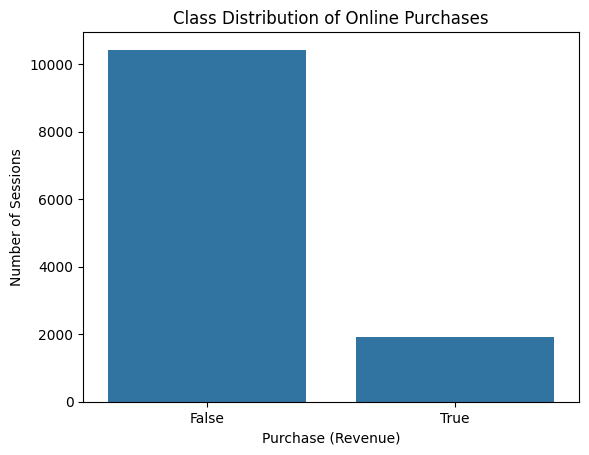

In [8]:
sns.countplot(x="Revenue", data=df)

plt.title("Class Distribution of Online Purchases")
plt.xlabel("Purchase (Revenue)")
plt.ylabel("Number of Sessions")

plt.show()

In [9]:
df["Revenue"] = df["Revenue"].astype(int)

X = df.drop("Revenue", axis=1)
y = df["Revenue"]

categorical_features = X.select_dtypes(
    include=["object", "bool"]
).columns

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

C:\Users\ASUS\AppData\Local\Temp\ipykernel_23812\607114088.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numerical_features),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features)
])

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 9864
Testing samples: 2466


In [11]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Logistic Regression - Original Data")
print("-----------------------------------")
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))

Logistic Regression - Original Data
-----------------------------------
Accuracy : 0.8811841038118411
Precision: 0.7431693989071039
Recall   : 0.35602094240837695
F1 Score : 0.4814159292035398


In [12]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Purchase", "Purchase"]
))

              precision    recall  f1-score   support

 No Purchase       0.89      0.98      0.93      2084
    Purchase       0.74      0.36      0.48       382

    accuracy                           0.88      2466
   macro avg       0.82      0.67      0.71      2466
weighted avg       0.87      0.88      0.86      2466



In [13]:
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

Before SMOTE:
Revenue
0    8338
1    1526
Name: count, dtype: int64

After SMOTE:
Revenue
0    8338
1    8338
Name: count, dtype: int64


In [14]:
model_smote = LogisticRegression(max_iter=1000)

model_smote.fit(X_train_smote, y_train_smote)

y_pred_smote = model_smote.predict(X_test)

print("Logistic Regression - After SMOTE")
print("----------------------------------")
print("Accuracy :", accuracy_score(y_test, y_pred_smote))
print("Precision:", precision_score(y_test, y_pred_smote))
print("Recall   :", recall_score(y_test, y_pred_smote))
print("F1 Score :", f1_score(y_test, y_pred_smote))

Logistic Regression - After SMOTE
----------------------------------
Accuracy : 0.8446877534468775
Precision: 0.4991364421416235
Recall   : 0.756544502617801
F1 Score : 0.6014568158168574


In [15]:
print(classification_report(
    y_test,
    y_pred_smote,
    target_names=["No Purchase", "Purchase"]
))

              precision    recall  f1-score   support

 No Purchase       0.95      0.86      0.90      2084
    Purchase       0.50      0.76      0.60       382

    accuracy                           0.84      2466
   macro avg       0.72      0.81      0.75      2466
weighted avg       0.88      0.84      0.86      2466



In [16]:
results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    
    "Original Data": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred)
    ],
    
    "After SMOTE": [
        accuracy_score(y_test, y_pred_smote),
        precision_score(y_test, y_pred_smote),
        recall_score(y_test, y_pred_smote),
        f1_score(y_test, y_pred_smote)
    ]
})

results

,Metric,Original Data,After SMOTE
0,Accuracy,0.881184,0.844688
1,Precision,0.743169,0.499136
2,Recall,0.356021,0.756545
3,F1 Score,0.481416,0.601457


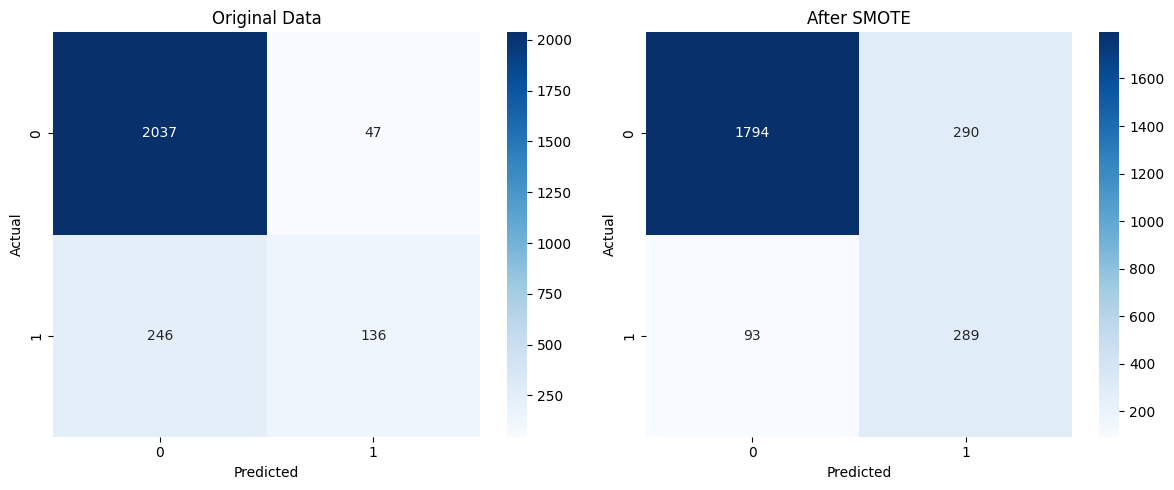

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0]
)

axes[0].set_title("Original Data")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    confusion_matrix(y_test, y_pred_smote),
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[1]
)

axes[1].set_title("After SMOTE")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [47]:
duration_columns = [
    "Administrative_Duration",
    "Informational_Duration",
    "ProductRelated_Duration"
]

print("Features selected for outlier treatment:")
print(duration_columns)

Features selected for outlier treatment:
['Administrative_Duration', 'Informational_Duration', 'ProductRelated_Duration']


In [49]:
X_duration = df.drop("Revenue", axis=1)
y_duration = df["Revenue"]

X_train_duration, X_test_duration, y_train_duration, y_test_duration = train_test_split(
    X_duration,
    y_duration,
    test_size=0.2,
    random_state=42,
    stratify=y_duration
)

print("Training samples:", X_train_duration.shape[0])
print("Testing samples:", X_test_duration.shape[0])

Training samples: 9864
Testing samples: 2466


In [51]:
duration_bounds = {}

for column in duration_columns:
    Q1 = X_train_duration[column].quantile(0.25)
    Q3 = X_train_duration[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    duration_bounds[column] = (lower_bound, upper_bound)

    print(f"{column}:")
    print(f"  Q1: {Q1:.2f}")
    print(f"  Q3: {Q3:.2f}")
    print(f"  IQR: {IQR:.2f}")
    print(f"  Lower Bound: {lower_bound:.2f}")
    print(f"  Upper Bound: {upper_bound:.2f}")
    print()

Administrative_Duration:
  Q1: 0.00
  Q3: 93.00
  IQR: 93.00
  Lower Bound: -139.50
  Upper Bound: 232.50

Informational_Duration:
  Q1: 0.00
  Q3: 0.00
  IQR: 0.00
  Lower Bound: 0.00
  Upper Bound: 0.00

ProductRelated_Duration:
  Q1: 182.57
  Q3: 1474.51
  IQR: 1291.94
  Lower Bound: -1755.35
  Upper Bound: 3412.42



In [53]:
for column in duration_columns:
    lower_bound, upper_bound = duration_bounds[column]

    outliers = (
        (X_train_duration[column] < lower_bound) |
        (X_train_duration[column] > upper_bound)
    )

    print(f"{column}: {outliers.sum()} outliers "
          f"({outliers.mean() * 100:.2f}%)")

Administrative_Duration: 933 outliers (9.46%)
Informational_Duration: 1926 outliers (19.53%)
ProductRelated_Duration: 746 outliers (7.56%)


In [55]:
X_train_duration_capped = X_train_duration.copy()
X_test_duration_capped = X_test_duration.copy()

for column in duration_columns:
    lower_bound, upper_bound = duration_bounds[column]

    X_train_duration_capped[column] = X_train_duration_capped[column].clip(
        lower=lower_bound,
        upper=upper_bound
    )

    X_test_duration_capped[column] = X_test_duration_capped[column].clip(
        lower=lower_bound,
        upper=upper_bound
    )

print("Duration outlier treatment completed.")

Duration outlier treatment completed.


In [57]:
preprocessor_duration = ColumnTransformer([
    ("num", StandardScaler(), numerical_features),
    ("cat", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ), categorical_features)
])

X_train_duration_processed = preprocessor_duration.fit_transform(
    X_train_duration_capped
)

X_test_duration_processed = preprocessor_duration.transform(
    X_test_duration_capped
)

print("Training shape:", X_train_duration_processed.shape)
print("Testing shape:", X_test_duration_processed.shape)

Training shape: (9864, 29)
Testing shape: (2466, 29)


In [59]:
model_duration = LogisticRegression(max_iter=1000)

model_duration.fit(
    X_train_duration_processed,
    y_train_duration
)

y_pred_duration = model_duration.predict(
    X_test_duration_processed
)

print("Logistic Regression - After Duration Outlier Treatment")
print("-------------------------------------------------------")
print("Accuracy :", accuracy_score(y_test_duration, y_pred_duration))
print("Precision:", precision_score(y_test_duration, y_pred_duration))
print("Recall   :", recall_score(y_test_duration, y_pred_duration))
print("F1 Score :", f1_score(y_test_duration, y_pred_duration))

Logistic Regression - After Duration Outlier Treatment
-------------------------------------------------------
Accuracy : 0.8803730738037308
Precision: 0.732620320855615
Recall   : 0.3586387434554974
F1 Score : 0.48154657293497366


In [61]:
print(classification_report(
    y_test_duration,
    y_pred_duration,
    target_names=["No Purchase", "Purchase"]
))

              precision    recall  f1-score   support

 No Purchase       0.89      0.98      0.93      2084
    Purchase       0.73      0.36      0.48       382

    accuracy                           0.88      2466
   macro avg       0.81      0.67      0.71      2466
weighted avg       0.87      0.88      0.86      2466



In [83]:
cm_duration = confusion_matrix(
    y_test_duration,
    y_pred_duration
)

print(cm_duration)

[[2034   50]
 [ 245  137]]


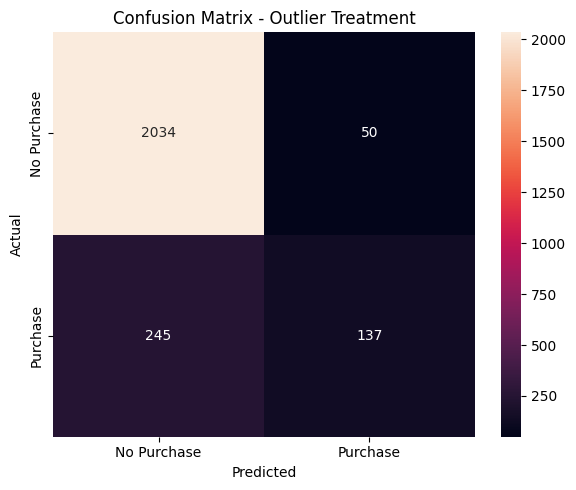

In [84]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_duration,
    annot=True,
    fmt="d",
    xticklabels=["No Purchase", "Purchase"],
    yticklabels=["No Purchase", "Purchase"]
)

plt.title("Confusion Matrix - Outlier Treatment")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

In [65]:
smote_duration = SMOTE(random_state=42)

X_train_duration_smote, y_train_duration_smote = smote_duration.fit_resample(
    X_train_duration_processed,
    y_train_duration
)

print("Before SMOTE:")
print(y_train_duration.value_counts())

print("\nAfter SMOTE:")
print(y_train_duration_smote.value_counts())

Before SMOTE:
Revenue
0    8338
1    1526
Name: count, dtype: int64

After SMOTE:
Revenue
0    8338
1    8338
Name: count, dtype: int64


In [67]:
model_combined = LogisticRegression(max_iter=1000)

model_combined.fit(
    X_train_duration_smote,
    y_train_duration_smote
)

y_pred_combined = model_combined.predict(
    X_test_duration_processed
)

print("Logistic Regression - Outlier Treatment + SMOTE")
print("------------------------------------------------")
print("Accuracy :", accuracy_score(y_test_duration, y_pred_combined))
print("Precision:", precision_score(y_test_duration, y_pred_combined))
print("Recall   :", recall_score(y_test_duration, y_pred_combined))
print("F1 Score :", f1_score(y_test_duration, y_pred_combined))

Logistic Regression - Outlier Treatment + SMOTE
------------------------------------------------
Accuracy : 0.8475263584752636
Precision: 0.5052816901408451
Recall   : 0.7513089005235603
F1 Score : 0.6042105263157894


In [69]:
print(classification_report(
    y_test_duration,
    y_pred_combined,
    target_names=["No Purchase", "Purchase"]
))

              precision    recall  f1-score   support

 No Purchase       0.95      0.87      0.91      2084
    Purchase       0.51      0.75      0.60       382

    accuracy                           0.85      2466
   macro avg       0.73      0.81      0.75      2466
weighted avg       0.88      0.85      0.86      2466



In [71]:
cm_combined = confusion_matrix(
    y_test_duration,
    y_pred_combined
)

print(cm_combined)

[[1803  281]
 [  95  287]]


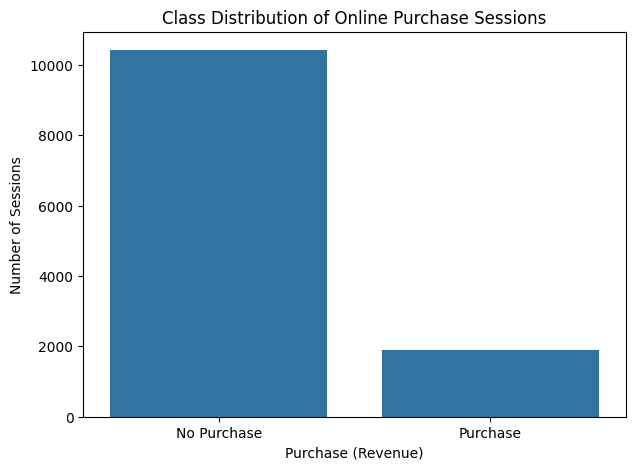

In [73]:
plt.figure(figsize=(7, 5))

sns.countplot(
    x="Revenue",
    data=df
)

plt.title("Class Distribution of Online Purchase Sessions")
plt.xlabel("Purchase (Revenue)")
plt.ylabel("Number of Sessions")

plt.xticks(
    [0, 1],
    ["No Purchase", "Purchase"]
)

plt.show()

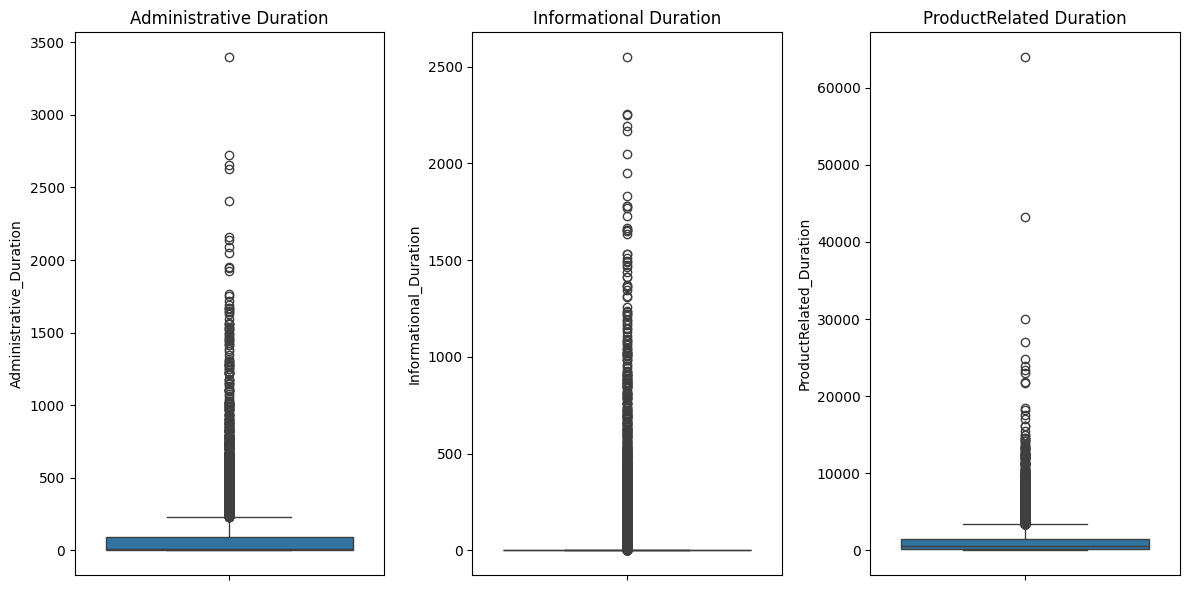

In [75]:
plt.figure(figsize=(12, 6))

for i, column in enumerate(duration_columns, 1):
    plt.subplot(1, 3, i)
    sns.boxplot(y=df[column])
    plt.title(column.replace("_", " "))

plt.tight_layout()
plt.show()

In [77]:
results = pd.DataFrame({
    "Model": [
        "Original",
        "SMOTE",
        "Outlier Treatment",
        "Outlier + SMOTE"
    ],
    "Accuracy": [
        0.8812,
        0.8447,
        0.8804,
        0.8475
    ],
    "Precision": [
        0.7432,
        0.4991,
        0.7326,
        0.5053
    ],
    "Recall": [
        0.3560,
        0.7565,
        0.3586,
        0.7513
    ],
    "F1 Score": [
        0.4814,
        0.6015,
        0.4815,
        0.6042
    ]
})

results

,Model,Accuracy,Precision,Recall,F1 Score
0,Original,0.8812,0.7432,0.3560,0.4814
1,SMOTE,0.8447,0.4991,0.7565,0.6015
2,Outlier Treatment,0.8804,0.7326,0.3586,0.4815
3,Outlier + SMOTE,0.8475,0.5053,0.7513,0.6042


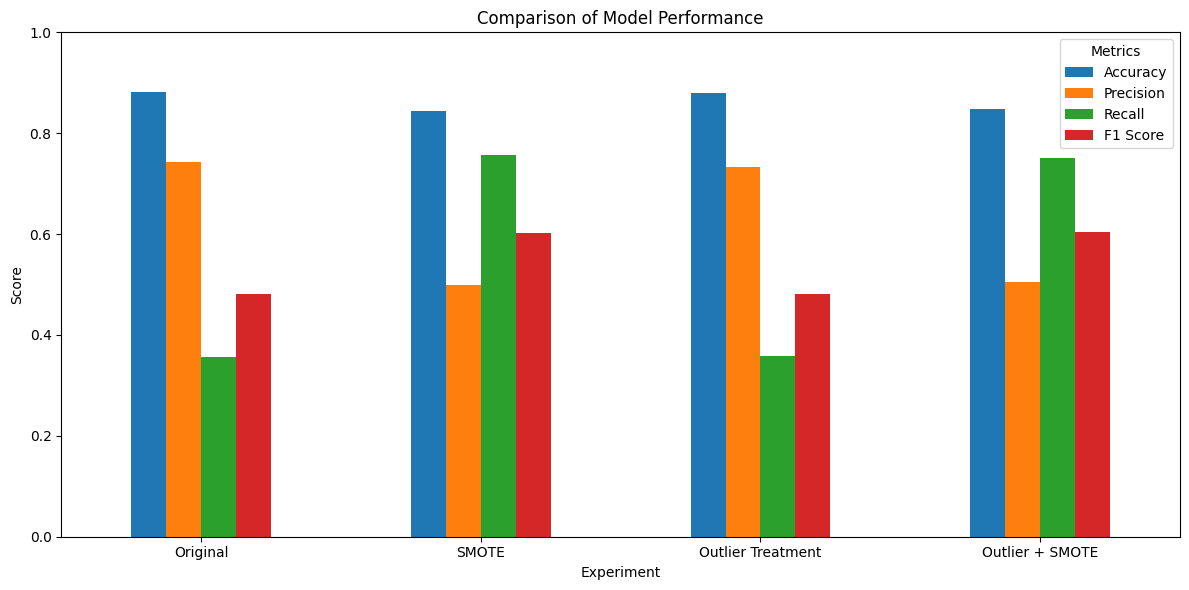

In [79]:
results_plot = results.set_index("Model")

results_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Comparison of Model Performance")
plt.xlabel("Experiment")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.xticks(rotation=0)
plt.legend(title="Metrics")

plt.tight_layout()
plt.show()

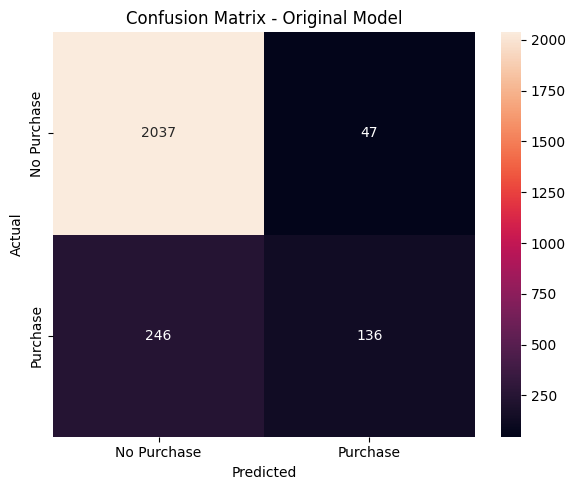

In [81]:
cm_original = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_original,
    annot=True,
    fmt="d",
    xticklabels=["No Purchase", "Purchase"],
    yticklabels=["No Purchase", "Purchase"]
)

plt.title("Confusion Matrix - Original Model")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

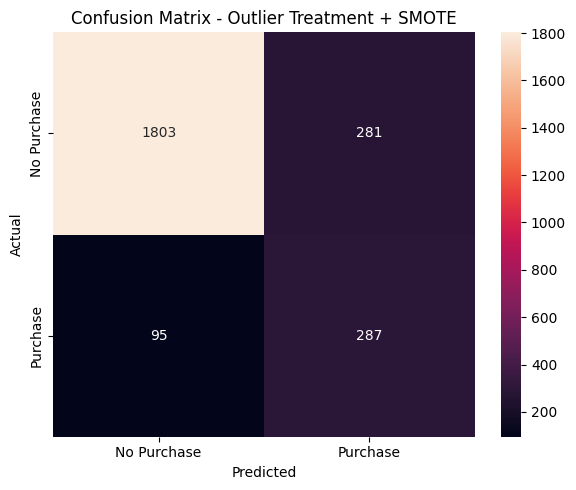

In [82]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_combined,
    annot=True,
    fmt="d",
    xticklabels=["No Purchase", "Purchase"],
    yticklabels=["No Purchase", "Purchase"]
)

plt.title("Confusion Matrix - Outlier Treatment + SMOTE")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()